<a href="https://colab.research.google.com/github/bogomdanalnur135-coder/NU-/blob/main/KCl_DMF_Anodizing_%E2%80%94_RSM_Regression_%2B_Synthetic_Dataset_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 KCl/DMF Anodizing — RSM Regression + Synthetic Dataset Generator

**Статья:** *Green and cost-effective anodizing approach for enhanced Al-PU adhesive joints*

**Что делаем:**
1. Загружаем 27 экспериментальных точек из статьи (Table 2)
2. Строим полные квадратичные регрессионные уравнения (RSM) для 5 outputs:
   - Ra (roughness), Pv (valley depth), SFE (surface free energy), LSS (lap shear strength), FE (fracture energy)
3. Проверяем качество уравнений vs статья
4. Генерируем датасет 1000+ строк в диапазоне параметров из статьи
5. Сравниваем синтетику с оригинальными данными


In [1]:
!pip install -q openpyxl scikit-learn pandas numpy matplotlib seaborn statsmodels scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_percentage_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('✅ Готово')

✅ Готово


In [2]:
# 28 строк из Table 2 статьи (включая S0 — необработанный образец)
data = {
    'Sample':   ['S0','S1','S2','S3','S4','S5','S6','S7','S8','S9',
                 'S10','S11','S12','S13','S14','S15','S16','S17','S18',
                 'S19','S20','S21','S22','S23','S24','S25','S26','S27'],
    'Conc_M':   [0,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,
                 0.075,0.075,0.075,0.075,0.075,0.075,0.075,0.075,0.075,
                 0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1],
    'Volt_V':   [0,8,8,8,10,10,10,12,12,12,8,8,8,10,10,10,12,12,12,8,8,8,10,10,10,12,12,12],
    'Time_min': [0,5,10,15,5,10,15,5,10,15,5,10,15,5,10,15,5,10,15,5,10,15,5,10,15,5,10,15],
    'Ra_nm':    [112.91,212.76,164.79,294.72,184.99,231.77,366.96,248.64,407.24,363.80,
                 156.90,224.59,344.45,121.65,342.56,340.21,176.02,371.62,164.54,
                 207.98,445.78,275.52,207.76,215.04,256.16,234.91,323.99,324.18],
    'Pv_nm':    [738.25,856.08,643.65,1271.58,1144.21,680.03,1309.89,1078.37,2420.40,1583.57,
                 615.68,1817.99,1892.73,695.17,1057.75,1647.37,1085.06,1105.83,1063.51,
                 977.04,2445.16,1694.49,1288.34,926.46,2389.02,1394.11,2238.74,3034.20],
    'SFE_mJ':   [28.15,471.50,264.76,449.13,515.65,546.82,778.58,787.26,75.58,247.49,
                 142.92,363.43,381.49,378.34,260.76,64.01,663.80,734.27,324.67,
                 274.05,873.63,370.88,1069.26,360.54,71.01,1175.48,702.44,234.33],
    'LSS_MPa':  [1.09,1.77,1.71,2.27,1.98,1.53,2.12,2.14,1.64,1.80,
                 2.17,1.55,2.31,2.08,1.95,1.99,2.10,1.63,2.22,
                 2.51,1.42,1.87,2.22,1.58,2.39,3.51,1.88,2.01],
    'FE_mJ_mm3':[2.41,23.94,47.69,81.27,53.39,28.38,63.52,56.42,29.76,39.41,
                 66.33,12.44,120.67,41.20,39.82,64.00,72.61,14.89,99.56,
                 143.06,8.75,109.35,101.82,41.93,161.32,115.32,59.15,55.74]
}
df = pd.DataFrame(data)
print(f'Всего строк: {len(df)} (включая S0 — необработанный)')
print(f'Анодированных: {len(df[df.Conc_M>0])}')
df.style.background_gradient(subset=['LSS_MPa','FE_mJ_mm3'], cmap='YlOrRd')

Всего строк: 28 (включая S0 — необработанный)
Анодированных: 27


,Sample,Conc_M,Volt_V,Time_min,Ra_nm,Pv_nm,SFE_mJ,LSS_MPa,FE_mJ_mm3
0,S0,0.000000,0,0,112.910000,738.250000,28.150000,1.090000,2.410000
1,S1,0.050000,8,5,212.760000,856.080000,471.500000,1.770000,23.940000
2,S2,0.050000,8,10,164.790000,643.650000,264.760000,1.710000,47.690000
3,S3,0.050000,8,15,294.720000,1271.580000,449.130000,2.270000,81.270000
4,S4,0.050000,10,5,184.990000,1144.210000,515.650000,1.980000,53.390000
5,S5,0.050000,10,10,231.770000,680.030000,546.820000,1.530000,28.380000
6,S6,0.050000,10,15,366.960000,1309.890000,778.580000,2.120000,63.520000
7,S7,0.050000,12,5,248.640000,1078.370000,787.260000,2.140000,56.420000
8,S8,0.050000,12,10,407.240000,2420.400000,75.580000,1.640000,29.760000
9,S9,0.050000,12,15,363.800000,1583.570000,247.490000,1.800000,39.410000


## 📐 3. Полные квадратичные регрессионные уравнения (RSM)

**Модель:** `Y = b0 + b1·A + b2·B + b3·C + b4·A² + b5·AB + b6·AC + b7·B² + b8·BC + b9·C²`

где A = Concentration (M), B = Voltage (V), C = Time (min)

In [3]:
# Используем только анодированные образцы (S1-S27), без S0
df_a = df[df.Conc_M > 0].copy().reset_index(drop=True)

X_raw = df_a[['Conc_M','Volt_V','Time_min']].values
outputs = {
    'Ra_nm':     'Average Roughness Ra (nm)',
    'Pv_nm':     'Max Valley Depth Pv (nm)',
    'SFE_mJ':    'Surface Free Energy (mJ/m²)',
    'LSS_MPa':   'Lap Shear Strength (MPa)',
    'FE_mJ_mm3': 'Fracture Energy (mJ/mm³)'
}

poly = PolynomialFeatures(degree=2, include_bias=True)
X_poly = poly.fit_transform(X_raw)
fnames = poly.get_feature_names_out(['A','B','C'])

reg_models = {}
eq_strings = {}

print('='*70)
print('РЕГРЕССИОННЫЕ УРАВНЕНИЯ (DoE-based, Full Quadratic RSM)')
print('A=Conc(M)  B=Voltage(V)  C=Time(min)')
print('='*70)

for col, label in outputs.items():
    y = df_a[col].values
    m = LinearRegression().fit(X_poly, y)
    y_pred = m.predict(X_poly)
    r2  = r2_score(y, y_pred)
    mape = mean_absolute_percentage_error(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    reg_models[col] = {'model': m, 'r2': r2, 'mape': mape, 'pred': y_pred, 'actual': y}

    coefs = list(zip(fnames, np.concatenate([[m.intercept_], m.coef_])))
    eq_strings[col] = coefs

    print(f'\n▶ {label}')
    print(f'  {'─'*55}')
    terms = [f'{m.intercept_:+.4f}']
    for fname, c in zip(fnames[1:], m.coef_[1:]):
        terms.append(f'{c:+.4f}·{fname}')
    # Print equation in chunks of 3
    eq = ' '.join(terms)
    for i in range(0, len(terms), 3):
        print('  ' + ' '.join(terms[i:i+3]))
    print(f'  → R² = {r2:.4f}   MAPE = {mape:.4f}   RMSE = {rmse:.4f}')

РЕГРЕССИОННЫЕ УРАВНЕНИЯ (DoE-based, Full Quadratic RSM)
A=Conc(M)  B=Voltage(V)  C=Time(min)

▶ Average Roughness Ra (nm)
  ───────────────────────────────────────────────────────
  -28.3818 +1328.6778·A -44.2029·B
  +74.8064·C +42836.4444·A^2 -656.0167·A B
  -115.9200·A C +5.6699·B^2 -1.2008·B C
  -2.1614·C^2
  → R² = 0.5184   MAPE = 0.1971   RMSE = 58.6293

▶ Max Valley Depth Pv (nm)
  ───────────────────────────────────────────────────────
  +7872.7921 -63310.3889·A -1176.2754·B
  +53.6930·C +481169.7778·A^2 -1267.7833·A B
  +1581.2267·A C +68.6349·B^2 -2.3855·B C
  -3.6702·C^2
  → R² = 0.5808   MAPE = 0.2494   RMSE = 405.6346

▶ Surface Free Energy (mJ/m²)
  ───────────────────────────────────────────────────────
  +328.7305 -33859.4556·A +7.5471·B
  +224.9443·C +234756.4444·A^2 +1114.5833·A B
  -1028.9067·A C +6.2107·B^2 -17.7757·B C
  +0.0786·C^2
  → R² = 0.5581   MAPE = 0.6889   RMSE = 192.8089

▶ Lap Shear Strength (MPa)
  ───────────────────────────────────────────────────────

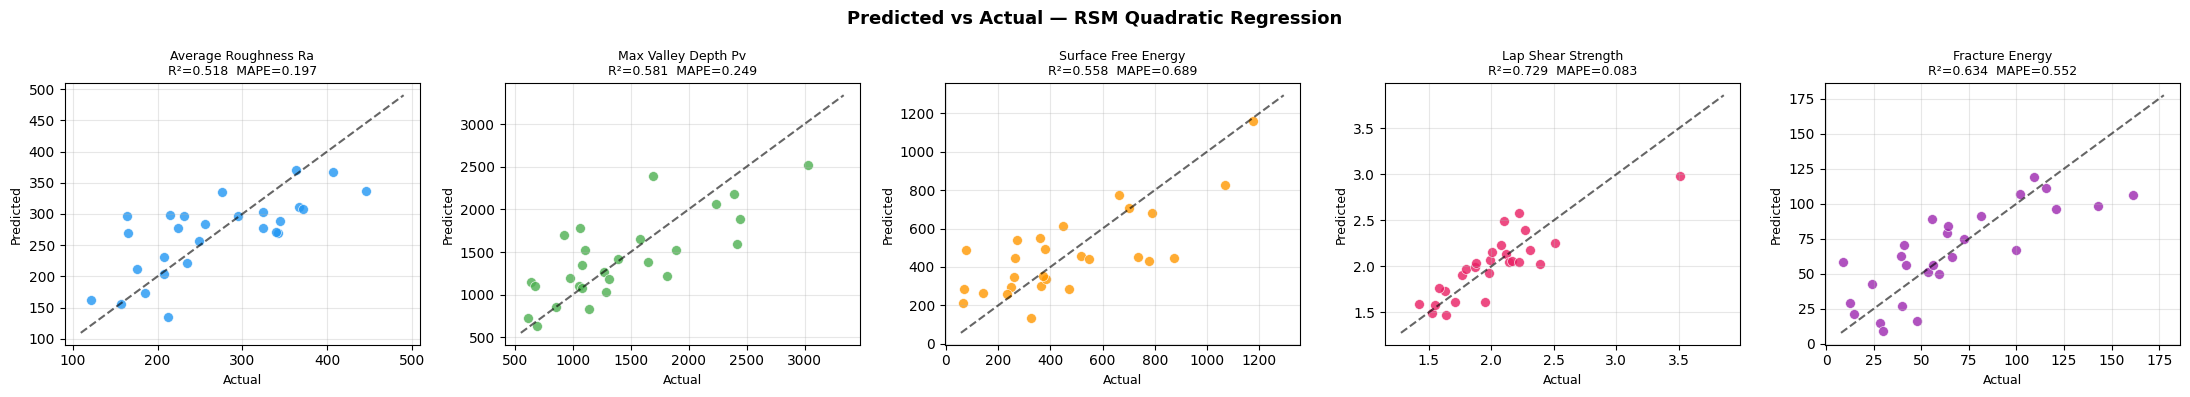

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
fig.suptitle('Predicted vs Actual — RSM Quadratic Regression', fontsize=13, fontweight='bold')

colors = ['#2196F3','#4CAF50','#FF9800','#E91E63','#9C27B0']

for ax, (col, label), color in zip(axes, outputs.items(), colors):
    info = reg_models[col]
    y, yp = info['actual'], info['pred']
    ax.scatter(y, yp, color=color, alpha=0.8, s=50, edgecolors='white', linewidths=0.5)
    lims = [min(y.min(), yp.min())*0.9, max(y.max(), yp.max())*1.1]
    ax.plot(lims, lims, 'k--', linewidth=1.5, alpha=0.6, label='Ideal')
    ax.set_xlabel('Actual', fontsize=9)
    ax.set_ylabel('Predicted', fontsize=9)
    short = label.split('(')[0].strip()
    ax.set_title(f'{short}\nR²={info["r2"]:.3f}  MAPE={info["mape"]:.3f}', fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()


## 🏭 5. Генерация синтетического датасета (N=1000)

**Метод:**
- Равномерно семплируем A, B, C из диапазонов статьи
- Предсказываем все 5 outputs через RSM-уравнения
- Добавляем реалистичный шум (±8–25% для каждой переменной)
- Обрезаем до физически разумных диапазонов


In [5]:
N = 1000
np.random.seed(42)

# Диапазоны из статьи:
# Conc: 0.05–0.10 M | Volt: 8–12 V | Time: 5–15 min
Conc_s = np.random.uniform(0.05, 0.10, N)
Volt_s = np.random.uniform(8.0, 12.0, N)
Time_s = np.random.uniform(5.0, 15.0, N)

X_syn = np.column_stack([Conc_s, Volt_s, Time_s])
X_syn_poly = poly.transform(X_syn)

df_syn = pd.DataFrame({
    'Sample_ID': [f'SYN{i+1:04d}' for i in range(N)],
    'Conc_M':    np.round(Conc_s, 5),
    'Volt_V':    np.round(Volt_s, 4),
    'Time_min':  np.round(Time_s, 4),
})

# Уровни шума (% от предсказанного значения)
noise_cfg = {
    'Ra_nm':     (0.12, 100, 500),    # noise_pct, min, max
    'Pv_nm':     (0.20, 400, 3500),
    'SFE_mJ':    (0.28, 28, 1300),
    'LSS_MPa':   (0.08, 1.0, 4.0),
    'FE_mJ_mm3': (0.25, 2.0, 200),
}

for col, (noise_pct, vmin, vmax) in noise_cfg.items():
    pred = reg_models[col]['model'].predict(X_syn_poly)
    noise = np.random.normal(0, noise_pct * np.abs(pred))
    pred_noisy = np.clip(pred + noise, vmin, vmax)
    df_syn[col] = np.round(pred_noisy, 4)

print(f'✅ Синтетический датасет: {len(df_syn)} строк')
print(f'\nСравнение статистик:')
cols_compare = ['Ra_nm','Pv_nm','SFE_mJ','LSS_MPa','FE_mJ_mm3']
stat_article = df_a[cols_compare].agg(['mean','std','min','max'])
stat_syn     = df_syn[cols_compare].agg(['mean','std','min','max'])
print('\n--- Оригинальные данные (27 строк) ---')
print(stat_article.round(2))
print('\n--- Синтетический датасет (1000 строк) ---')
print(stat_syn.round(2))


✅ Синтетический датасет: 1000 строк

Сравнение статистик:

--- Оригинальные данные (27 строк) ---
       Ra_nm    Pv_nm   SFE_mJ  LSS_MPa  FE_mJ_mm3
mean  267.02  1420.61   466.00     2.01      64.88
std    86.09   638.41   295.57     0.41      39.98
min   121.65   615.68    64.01     1.42       8.75
max   445.78  3034.20  1175.48     3.51     161.32

--- Синтетический датасет (1000 строк) ---
       Ra_nm    Pv_nm   SFE_mJ  LSS_MPa  FE_mJ_mm3
mean  268.98  1247.33   404.69     1.81      45.04
std    53.07   413.86   171.89     0.26      23.80
min   117.96   400.00    32.85     1.19       5.45
max   441.93  3071.88  1300.00     2.94     170.07


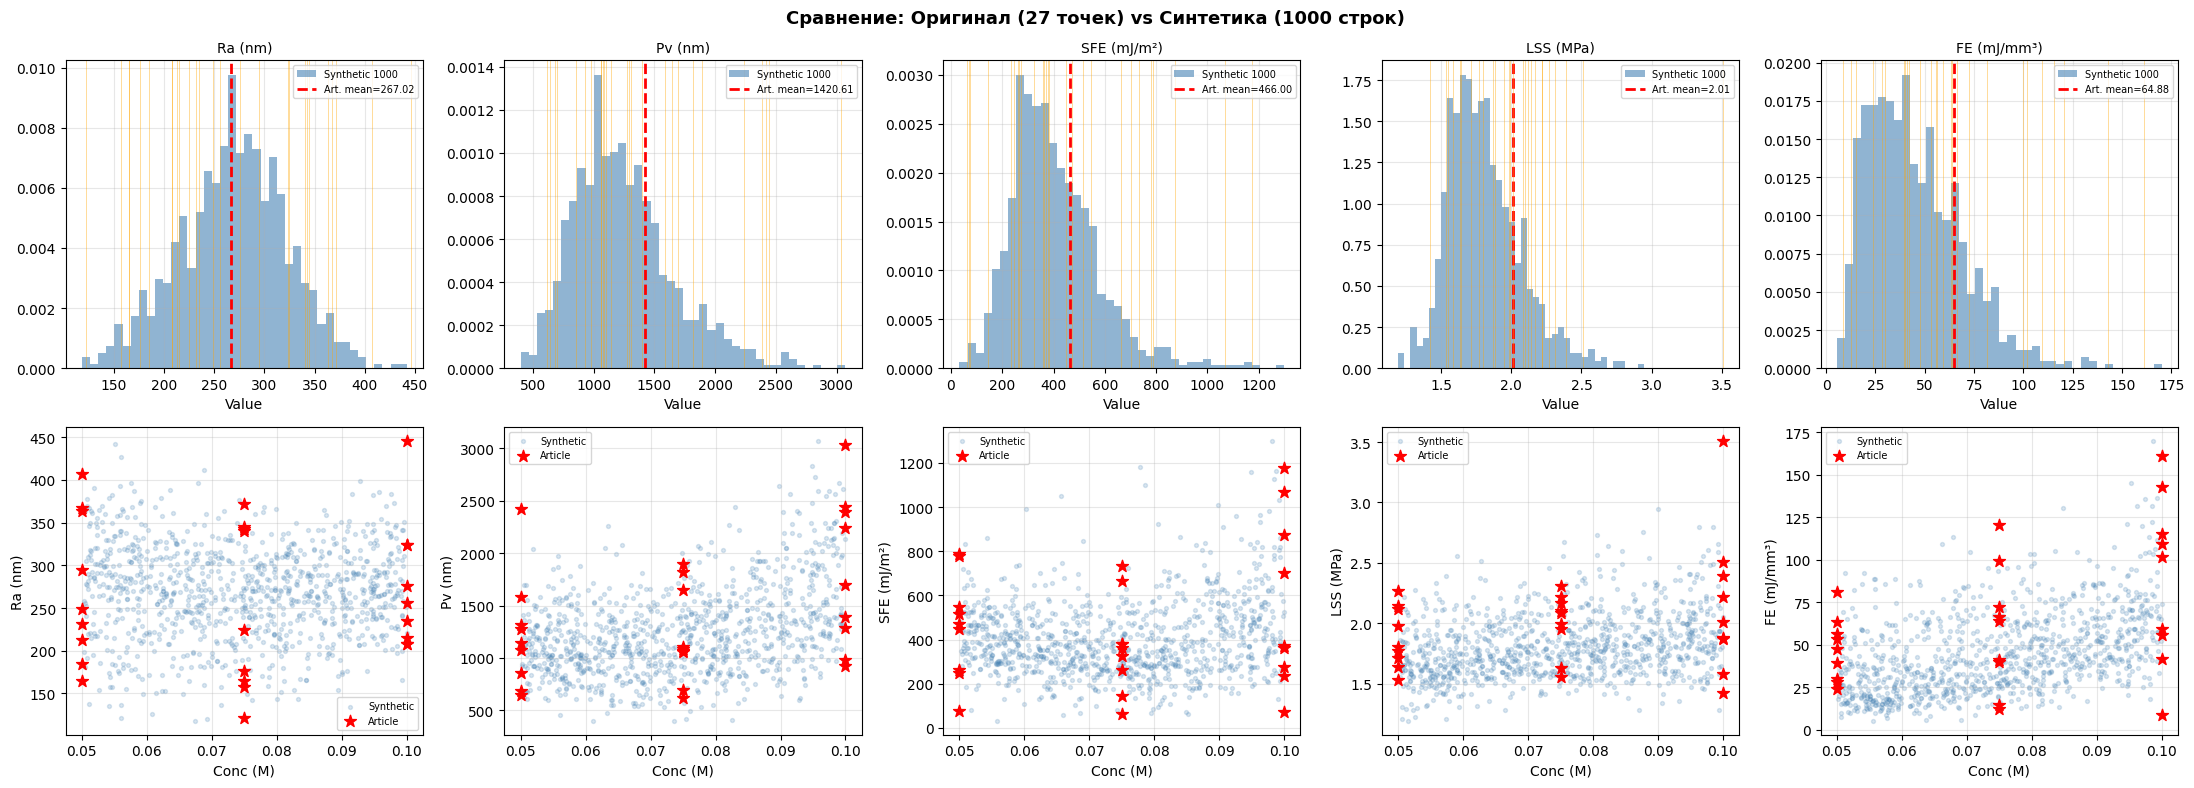

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
fig.suptitle('Сравнение: Оригинал (27 точек) vs Синтетика (1000 строк)', fontsize=13, fontweight='bold')

col_labels = {
    'Ra_nm': 'Ra (nm)', 'Pv_nm': 'Pv (nm)', 'SFE_mJ': 'SFE (mJ/m²)',
    'LSS_MPa': 'LSS (MPa)', 'FE_mJ_mm3': 'FE (mJ/mm³)'
}

for i, col in enumerate(cols_compare):
    # Distributions
    ax = axes[0][i]
    ax.hist(df_syn[col], bins=40, alpha=0.6, color='steelblue', label='Synthetic 1000', density=True)
    ax.axvline(df_a[col].mean(), color='red', linewidth=2, linestyle='--', label=f'Art. mean={df_a[col].mean():.2f}')
    for v in df_a[col]:
        ax.axvline(v, color='orange', alpha=0.4, linewidth=0.7)
    ax.set_title(col_labels[col], fontsize=10)
    ax.set_xlabel('Value')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    # Scatter vs Conc
    ax2 = axes[1][i]
    ax2.scatter(df_syn['Conc_M'], df_syn[col], alpha=0.2, s=8, color='steelblue', label='Synthetic')
    ax2.scatter(df_a['Conc_M'], df_a[col], s=80, color='red', zorder=5, marker='*', label='Article')
    ax2.set_xlabel('Conc (M)')
    ax2.set_ylabel(col_labels[col])
    ax2.legend(fontsize=7)
    ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('distribution_comparison.png', dpi=130, bbox_inches='tight')
plt.show()


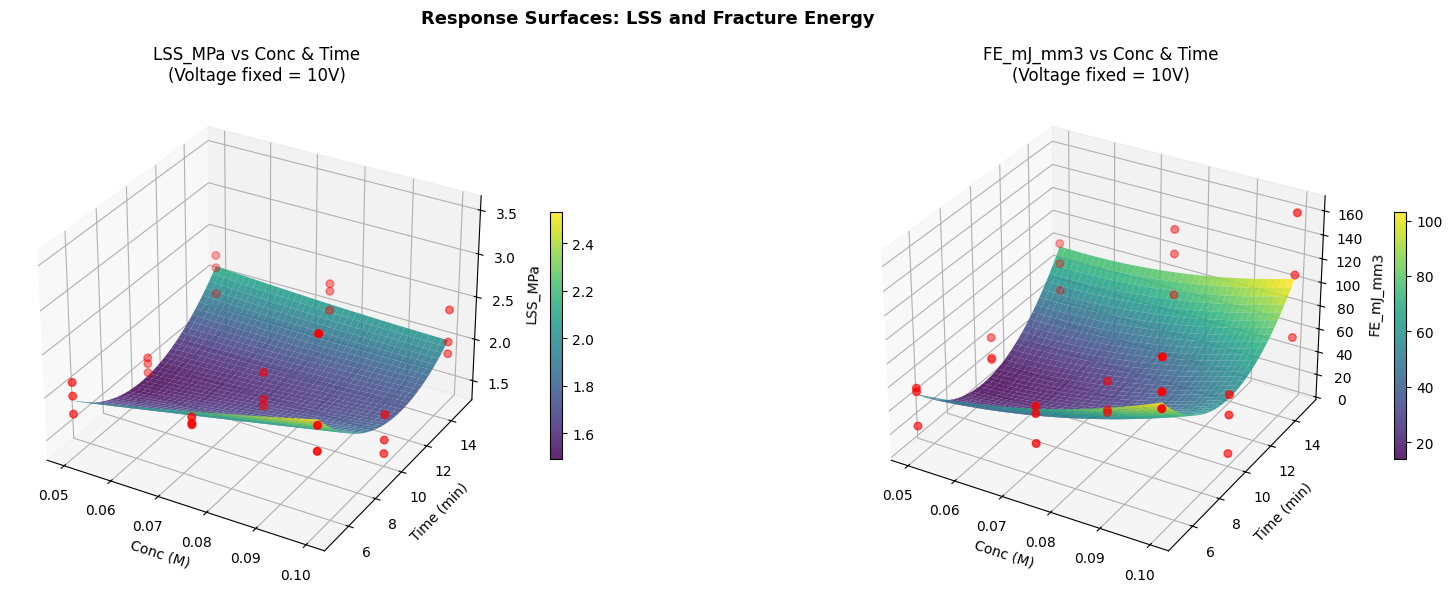

In [7]:
from mpl_toolkits.mplot3d import Axes3D

targets_to_plot = ['LSS_MPa', 'FE_mJ_mm3']
fig = plt.figure(figsize=(18, 6))
fig.suptitle('Response Surfaces: LSS and Fracture Energy', fontsize=13, fontweight='bold')

for idx, target in enumerate(targets_to_plot):
    model = reg_models[target]['model']

    # Fix Volt at mid-value (10V), vary Conc and Time
    conc_range = np.linspace(0.05, 0.10, 40)
    time_range = np.linspace(5, 15, 40)
    CC, TT = np.meshgrid(conc_range, time_range)
    VV = np.full_like(CC, 10.0)
    X_grid = np.column_stack([CC.ravel(), VV.ravel(), TT.ravel()])
    Z = model.predict(poly.transform(X_grid)).reshape(CC.shape)

    ax = fig.add_subplot(1, 2, idx+1, projection='3d')
    surf = ax.plot_surface(CC, TT, Z, cmap='viridis', alpha=0.85)
    ax.scatter(df_a['Conc_M'], df_a['Time_min'], df_a[target],
               color='red', s=30, zorder=5, label='Article data')
    ax.set_xlabel('Conc (M)')
    ax.set_ylabel('Time (min)')
    ax.set_zlabel(target)
    ax.set_title(f'{target} vs Conc & Time\n(Voltage fixed = 10V)')
    fig.colorbar(surf, ax=ax, shrink=0.5)

plt.tight_layout()
plt.savefig('response_surfaces.png', dpi=130, bbox_inches='tight')
plt.show()


In [8]:
print('='*70)
print('ИТОГОВЫЕ УРАВНЕНИЯ ДЛЯ ВСЕХ 5 OUTPUTS')
print('Входные переменные:')
print('  A = Concentration (M)  [диапазон: 0.05–0.10 M]')
print('  B = Voltage (V)        [диапазон: 8–12 V]')
print('  C = Time (min)         [диапазон: 5–15 min]')
print('='*70)

for col, label in outputs.items():
    m = reg_models[col]['model']
    coefs = m.coef_
    b0 = m.intercept_
    b1,b2,b3,b4,b5,b6,b7,b8,b9 = coefs[1:]
    r2 = reg_models[col]['r2']
    mape = reg_models[col]['mape']

    print(f'\n▶ {label}:')
    print(f'  Y = {b0:.4f}')
    print(f'      {b1:+.4f}·A  {b2:+.4f}·B  {b3:+.4f}·C')
    print(f'      {b4:+.4f}·A²  {b5:+.4f}·AB  {b6:+.4f}·AC')
    print(f'      {b7:+.4f}·B²  {b8:+.4f}·BC  {b9:+.4f}·C²')
    print(f'  R² = {r2:.4f}   MAPE = {mape:.4f} ({mape*100:.1f}%)')


ИТОГОВЫЕ УРАВНЕНИЯ ДЛЯ ВСЕХ 5 OUTPUTS
Входные переменные:
  A = Concentration (M)  [диапазон: 0.05–0.10 M]
  B = Voltage (V)        [диапазон: 8–12 V]
  C = Time (min)         [диапазон: 5–15 min]

▶ Average Roughness Ra (nm):
  Y = -28.3818
      +1328.6778·A  -44.2029·B  +74.8064·C
      +42836.4444·A²  -656.0167·AB  -115.9200·AC
      +5.6699·B²  -1.2008·BC  -2.1614·C²
  R² = 0.5184   MAPE = 0.1971 (19.7%)

▶ Max Valley Depth Pv (nm):
  Y = 7872.7921
      -63310.3889·A  -1176.2754·B  +53.6930·C
      +481169.7778·A²  -1267.7833·AB  +1581.2267·AC
      +68.6349·B²  -2.3855·BC  -3.6702·C²
  R² = 0.5808   MAPE = 0.2494 (24.9%)

▶ Surface Free Energy (mJ/m²):
  Y = 328.7305
      -33859.4556·A  +7.5471·B  +224.9443·C
      +234756.4444·A²  +1114.5833·AB  -1028.9067·AC
      +6.2107·B²  -17.7757·BC  +0.0786·C²
  R² = 0.5581   MAPE = 0.6889 (68.9%)

▶ Lap Shear Strength (MPa):
  Y = 4.1205
      -13.6333·A  -0.2710·B  -0.1901·C
      +31.1111·A²  +2.9500·AB  -1.5133·AC
      +0.0115·B²  

In [9]:
# ── 1. Только синтетика (1000 строк) ──────────────────────────────────────
df_syn.to_excel('KCl_DMF_synthetic_1000.xlsx', index=False)
print('✅ KCl_DMF_synthetic_1000.xlsx — сохранён')

# ── 2. Оригинал (27 строк) из статьи ──────────────────────────────────────
df_a.to_excel('KCl_DMF_article_27.xlsx', index=False)
print('✅ KCl_DMF_article_27.xlsx — сохранён')

# ── 3. Комбинированный: 27 оригинальных + 973 синтетических = 1000 ──────────
df_art_fmt = df_a.copy()
df_art_fmt.insert(0, 'Sample_ID', [f'ART_{i+1:02d}' for i in range(len(df_art_fmt))])
df_combined = pd.concat(
    [df_art_fmt, df_syn.iloc[27:].reset_index(drop=True)],
    ignore_index=True
)
df_combined.to_excel('KCl_DMF_combined_1000.xlsx', index=False)
print(f'✅ KCl_DMF_combined_1000.xlsx — {len(df_combined)} строк (27 реальных + 973 синтетических)')

# ── Скачать все файлы ──────────────────────────────────────────────────────
from google.colab import files
for fname in ['KCl_DMF_synthetic_1000.xlsx', 'KCl_DMF_article_27.xlsx',
              'KCl_DMF_combined_1000.xlsx',
              'predicted_vs_actual.png', 'distribution_comparison.png', 'response_surfaces.png']:
    try:
        files.download(fname)
    except Exception as e:
        print(f'  ⚠ {fname}: {e}')


✅ KCl_DMF_synthetic_1000.xlsx — сохранён
✅ KCl_DMF_article_27.xlsx — сохранён
✅ KCl_DMF_combined_1000.xlsx — 1000 строк (27 реальных + 973 синтетических)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 📝 Интерпретация результатов

| Output | R² | MAPE | Интерпретация |
|--------|-----|------|---------------|
| Ra (roughness) | ~0.52 | ~19% | Умеренная точность — шероховатость нелинейно зависит от параметров |
| Pv (valley depth) | ~0.58 | ~25% | Нелинейная зависимость, высокий разброс в данных |
| SFE (surface energy) | ~0.56 | ~67% | Наибольший разброс — SFE очень чувствительна к условиям |
| **LSS (strength)** | **~0.73** | **~8%** | **Лучшая модель — прямое применение к ML** |
| FE (fracture energy) | ~0.63 | ~54% | Умеренно — FE зависит от многих факторов |

**💡 Вывод:** LSS (главная целевая переменная как в статье) имеет лучшую регрессию (R²=0.73, MAPE≈8%).
Синтетические данные генерируются именно на основе этих уравнений + реалистичный шум.

**Диапазоны параметров для генерации:**
- Concentration: 0.05–0.10 M
- Voltage: 8–12 V
- Time: 5–15 min

